# Day 1 — Build your first predictive model

## Step 0: Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator

In [2]:
df = pd.read_csv("../data/raw/diabetic_data.csv",
                 keep_default_na=False,
                 na_values=["?"],
                 dtype={"payer_code": "str"})

## replace '?" with NA
#df = df.replace("?", pd.NA)

In [3]:
str_cols = df.select_dtypes(include=['str']).columns
str_cols = str_cols[ ~str_cols.isin( ['age', 'weight' ] ) ]
df[str_cols] = df[str_cols].astype('category')

In [4]:
## now set the order of some of the variables
age_order = [  '[0-10)',  '[10-20)',  '[20-30)',  '[30-40)',  '[40-50)',  '[50-60)',
  '[60-70)',  '[70-80)',  '[80-90)', '[90-100)']

age_type = pd.CategoricalDtype( categories=age_order,
                                ordered=True )
df["age"] = df["age"].astype(age_type)

weight_order = [ "[0-25)", "[25-50)", "[50-75)", "[75-100)",
                 "[100-125)", "[125-150)", "[150-175)",
                 "[175-200)", ">200" ]
weight_type = pd.CategoricalDtype( categories=weight_order,
                                   ordered=True )
df["weight"] = df["weight"].astype(weight_type)

In [5]:
# Returns an Index of column names containing '_id'
id_cols = df.columns[df.columns.str.contains('_id')]
id_cols = id_cols[ ~id_cols.isin( ["encounter_id"] ) ]
id_cols
df[ id_cols ] = df[ id_cols ].astype('category')

In [6]:
cat_cols = id_cols.append( str_cols )

## Day 5: Prepare the modeling dataset

In [7]:
df[ "readmit_30_label" ] = [ "Early" if x == "<30" else "Later" for x in df[ "readmitted" ] ]
labels = df[ "readmit_30_label" ]
##X = df.drop(columns=["readmit_30_02", "readmit_30", "readmitted", "patient_nbr", "encounter_id"])
features_to_model = "num_procedures number_outpatient number_emergency number_inpatient A1Cresult metformin discharge_disposition_id diabetesMed admission_source_id admission_type_id max_glu_serum".split()
X = df[ features_to_model ]

In [15]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.model_selection import StratifiedGroupKFold

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
##sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

y=labels
train_idx, test_idx = next( gss.split( X, groups=df[ "patient_nbr" ] ) )

In [18]:
X_train = X.iloc[ train_idx ]
X_test = X.iloc[ test_idx ]
y_train = y.iloc[ train_idx ]
y_test = y.iloc[ test_idx ]

In [20]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="prior")
dummy.fit(X_train, y_train)
print(dummy.score(X_test, y_test))

0.893266511189401


In [37]:
dummy_preds = dummy.predict(X_test)
dummy_probs = dummy.predict_proba( X_test )
dummy_log_probs = dummy.predict_log_proba( X_test )

In [77]:
from sklearn.metrics import classification_report
print( classification_report( y_test, dummy.predict( X_test ) ) )

              precision    recall  f1-score   support

       Early       0.00      0.00      0.00      2151
       Later       0.89      1.00      0.94     18002

    accuracy                           0.89     20153
   macro avg       0.45      0.50      0.47     20153
weighted avg       0.80      0.89      0.84     20153



/home/phw2006/devel/github_repos/personal_projects/Diabetes_130_US_hospitals_1999-2008/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/phw2006/devel/github_repos/personal_projects/Diabetes_130_US_hospitals_1999-2008/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/phw2006/devel/github_repos/personal_projects/Diabetes_130_US_hospitals_1999-2008/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precisi

In [66]:
from sklearn.metrics import roc_curve
pos_idx = list(dummy.classes_).index("Early")
y_score = dummy.predict_proba(X_test)[:, pos_idx]

fpr, tpr, thresholds = roc_curve( y_test, y_score, pos_label='Early' )
display(fpr)
display( tpr )
display( thresholds )

array([0., 1.])

array([0., 1.])

array([       inf, 0.11280066])

In [67]:
from sklearn.metrics import precision_recall_curve
pos_idx = list(dummy.classes_).index("Early")
y_score = dummy.predict_proba(X_test)[:, pos_idx]

precision, recall, thresholds = precision_recall_curve( y_test, y_score, pos_label='Early' )
display(precision)
display( recall )
display( thresholds )

array([0.10673349, 1.        ])

array([1., 0.])

array([0.11280066])

In [86]:
from sklearn.metrics import roc_auc_score
pos_idx = list(dummy.classes_).index("Early")
y_score = dummy.predict_proba(X_test)[:, pos_idx]

roc_auc_score(y_test == "Early", y_score)

0.5

In [70]:
from sklearn.metrics import average_precision_score
pos_idx = list(clf.classes_).index("Early")
y_score = clf.predict_proba(X_test)[:, pos_idx]

average_precision_score( y_test, y_score, pos_label='Early' )

0.10673348881059892

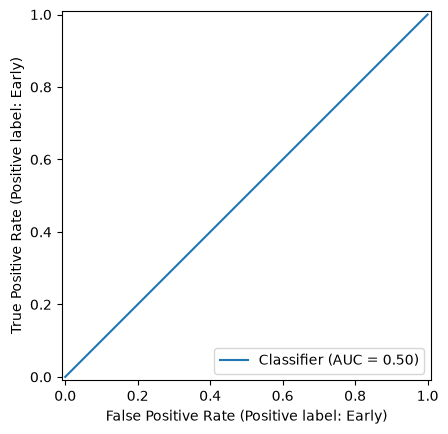

In [78]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

pos_idx = list(dummy.classes_).index("Early")
y_score = dummy.predict_proba(X_test)[:, pos_idx]
RocCurveDisplay.from_predictions(y_test, y_score, pos_label="Early")
plt.show()

## Repeat with the LogisticRegression classifier

In [52]:
## from: https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectPercentile, chi2
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import make_column_selector as selector

np.random.seed(0)
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)

categorical_transformer = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, selector(dtype_include=np.number)),
        ("cat", categorical_transformer, selector(dtype_include="category")),
    ]
)

In [54]:
from sklearn.linear_model import LogisticRegression

np.random.seed(0)
## from the columnTransformer page on scikit learn:
##https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html?utm_source=chatgpt.com

clf = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", LogisticRegression())]
).set_output(transform="pandas")

##X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

clf.fit(X_train, y_train)
print("model score: %.3f" % clf.score(X_test, y_test))

model score: 0.893


In [76]:
from sklearn.metrics import classification_report
print( classification_report( y_test, clf.predict( X_test ) ) )

              precision    recall  f1-score   support

       Early       0.41      0.01      0.02      2151
       Later       0.89      1.00      0.94     18002

    accuracy                           0.89     20153
   macro avg       0.65      0.50      0.48     20153
weighted avg       0.84      0.89      0.84     20153



In [79]:
from sklearn.metrics import roc_curve
pos_idx = list(clf.classes_).index("Early")
y_score = clf.predict_proba(X_test)[:, pos_idx]

fpr, tpr, thresholds = roc_curve( y_test, y_score, pos_label='Early' )
display(fpr)
display( tpr )
display( thresholds )

array([0.00000000e+00, 5.55493834e-05, 1.11098767e-04, ...,
       9.99666704e-01, 9.99777802e-01, 1.00000000e+00], shape=(4293,))

array([0., 0., 0., ..., 1., 1., 1.], shape=(4293,))

array([       inf, 0.79899844, 0.788842  , ..., 0.0013418 , 0.0013333 ,
       0.00117484], shape=(4293,))

In [80]:
from sklearn.metrics import precision_recall_curve
pos_idx = list(clf.classes_).index("Early")
y_score = clf.predict_proba(X_test)[:, pos_idx]

precision, recall, thresholds = precision_recall_curve( y_test, y_score, pos_label='Early' )
display(precision)
display( recall )
display( thresholds )

array([0.10673349, 0.10673879, 0.10674408, ..., 0.        , 0.        ,
       1.        ], shape=(7436,))

array([1., 1., 1., ..., 0., 0., 0.], shape=(7436,))

array([0.00117484, 0.00118447, 0.00127162, ..., 0.76503673, 0.788842  ,
       0.79899844], shape=(7435,))

In [84]:
from sklearn.metrics import roc_auc_score
pos_idx = list(clf.classes_).index("Early")
y_score = clf.predict_proba(X_test)[:, pos_idx]

roc_auc_score(y_test == "Early", y_score)

0.6606683662557046

In [82]:
from sklearn.metrics import average_precision_score
pos_idx = list(clf.classes_).index("Early")
y_score = clf.predict_proba(X_test)[:, pos_idx]

average_precision_score( y_test, y_score, pos_label='Early' )

0.2000450679787827

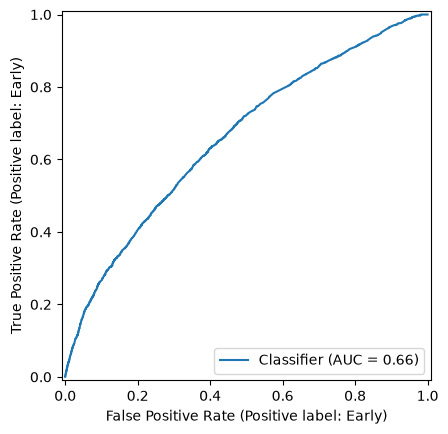

In [83]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

pos_idx = list(clf.classes_).index("Early")
y_score = clf.predict_proba(X_test)[:, pos_idx]
RocCurveDisplay.from_predictions(y_test, y_score, pos_label="Early")
plt.show()

### Let's try logistic regression with class_weight='balanced'

In [94]:
from sklearn.linear_model import LogisticRegression

np.random.seed(0)
## from the columnTransformer page on scikit learn:
##https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html?utm_source=chatgpt.com

bclf = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", LogisticRegression(class_weight='balanced', max_iter=1000))]
).set_output(transform="pandas")

##X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

bclf.fit(X_train, y_train)
print("model score: %.3f" % bclf.score(X_test, y_test))

model score: 0.691


In [87]:
from sklearn.metrics import classification_report
print( classification_report( y_test, bclf.predict( X_test ) ) )

              precision    recall  f1-score   support

       Early       0.17      0.51      0.26      2151
       Later       0.92      0.71      0.80     18002

    accuracy                           0.69     20153
   macro avg       0.55      0.61      0.53     20153
weighted avg       0.84      0.69      0.75     20153



In [88]:
from sklearn.metrics import roc_curve
pos_idx = list(bclf.classes_).index("Early")
y_score = bclf.predict_proba(X_test)[:, pos_idx]

fpr, tpr, thresholds = roc_curve( y_test, y_score, pos_label='Early' )
display(fpr)
display( tpr )
display( thresholds )

array([0.00000000e+00, 5.55493834e-05, 1.11098767e-04, ...,
       9.99500056e-01, 9.99611154e-01, 1.00000000e+00], shape=(4353,))

array([0., 0., 0., ..., 1., 1., 1.], shape=(4353,))

array([       inf, 0.98307688, 0.9760659 , ..., 0.00269777, 0.00263565,
       0.00240487], shape=(4353,))

In [89]:
from sklearn.metrics import precision_recall_curve
pos_idx = list(bclf.classes_).index("Early")
y_score = bclf.predict_proba(X_test)[:, pos_idx]

precision, recall, thresholds = precision_recall_curve( y_test, y_score, pos_label='Early' )
display(precision)
display( recall )
display( thresholds )

array([0.10673349, 0.10673879, 0.10674408, ..., 0.        , 0.        ,
       1.        ], shape=(7437,))

array([1., 1., 1., ..., 0., 0., 0.], shape=(7437,))

array([0.00240487, 0.0024579 , 0.00248325, ..., 0.97548542, 0.9760659 ,
       0.98307688], shape=(7436,))

In [90]:
from sklearn.metrics import roc_auc_score
pos_idx = list(bclf.classes_).index("Early")
y_score = bclf.predict_proba(X_test)[:, pos_idx]

roc_auc_score(y_test == "Early", y_score)

0.6615601262548906

In [91]:
from sklearn.metrics import average_precision_score
pos_idx = list(bclf.classes_).index("Early")
y_score = bclf.predict_proba(X_test)[:, pos_idx]

average_precision_score( y_test, y_score, pos_label='Early' )

0.20108148525235275

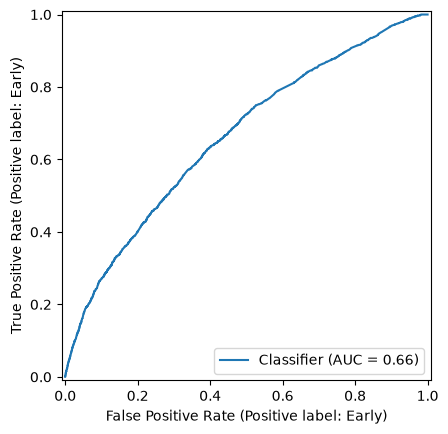

In [95]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

pos_idx = list(bclf.classes_).index("Early")
y_score = bclf.predict_proba(X_test)[:, pos_idx]
RocCurveDisplay.from_predictions(y_test, y_score, pos_label="Early")
plt.show()

## Day 3: Regularization and cross-validation

### Regularization

In [98]:
## by default, LogisticRegression uses 2 params
##   - C to control the strength of regularization, and 
##   - l1_ratio to control the mix or utilization of the l1 and l2 constraints
##  with the default values of C=1, and l1_ratio=0 (all l2; no elastic net, no l1)
## NOTE: LogisticRegression doesn't allow l1_ratio to be assigned to non-0 values when class_weight='balanced'


In [105]:
from sklearn.linear_model import LogisticRegression

np.random.seed(0)
## from the columnTransformer page on scikit learn:
##https://scikit-learn.org/stable/auto_examples/compose/plot_column_transformer_mixed_types.html?utm_source=chatgpt.com

rclf = Pipeline(
    steps=[("preprocessor", preprocessor), 
           ("classifier", LogisticRegression(solver='saga',
                                             C=10,
                                             l1_ratio=0.25,
                                              max_iter=2000))]
).set_output(transform="pandas")

##X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

rclf.fit(X_train, y_train)
print("model score: %.3f" % rclf.score(X_test, y_test))

model score: 0.893


In [104]:
print(rclf.score(X_test, y_test))

0.8927703071503003


In [106]:
from sklearn.metrics import classification_report
print( classification_report( y_test, rclf.predict( X_test ) ) )

              precision    recall  f1-score   support

       Early       0.40      0.01      0.02      2151
       Later       0.89      1.00      0.94     18002

    accuracy                           0.89     20153
   macro avg       0.65      0.50      0.48     20153
weighted avg       0.84      0.89      0.84     20153



In [107]:
from sklearn.metrics import roc_curve
pos_idx = list(rclf.classes_).index("Early")
y_score = rclf.predict_proba(X_test)[:, pos_idx]

fpr, tpr, thresholds = roc_curve( y_test, y_score, pos_label='Early' )
display(fpr)
display( tpr )
display( thresholds )

array([0.00000000e+00, 5.55493834e-05, 1.11098767e-04, ...,
       9.99722253e-01, 9.99833352e-01, 1.00000000e+00], shape=(4379,))

array([0., 0., 0., ..., 1., 1., 1.], shape=(4379,))

array([           inf, 7.99004190e-01, 7.87424399e-01, ...,
       7.66890778e-04, 7.61869784e-04, 6.86109853e-04], shape=(4379,))

In [108]:
from sklearn.metrics import precision_recall_curve
pos_idx = list(rclf.classes_).index("Early")
y_score = rclf.predict_proba(X_test)[:, pos_idx]

precision, recall, thresholds = precision_recall_curve( y_test, y_score, pos_label='Early' )
display(precision)
display( recall )
display( thresholds )

array([0.10673349, 0.10673879, 0.10674408, ..., 0.        , 0.        ,
       1.        ], shape=(7436,))

array([1., 1., 1., ..., 0., 0., 0.], shape=(7436,))

array([6.86109853e-04, 6.92760511e-04, 7.31312683e-04, ...,
       7.63994938e-01, 7.87424399e-01, 7.99004190e-01], shape=(7435,))

In [109]:
from sklearn.metrics import roc_auc_score
pos_idx = list(rclf.classes_).index("Early")
y_score = rclf.predict_proba(X_test)[:, pos_idx]

roc_auc_score(y_test == "Early", y_score)

0.6609372552282661

In [110]:
from sklearn.metrics import average_precision_score
pos_idx = list(rclf.classes_).index("Early")
y_score = rclf.predict_proba(X_test)[:, pos_idx]

average_precision_score( y_test, y_score, pos_label='Early' )

0.20062476203413288

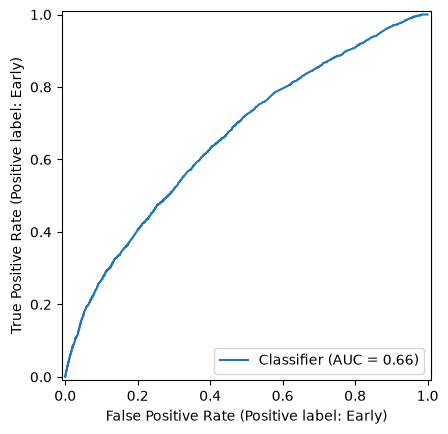

In [111]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

pos_idx = list(rclf.classes_).index("Early")
y_score = rclf.predict_proba(X_test)[:, pos_idx]
RocCurveDisplay.from_predictions(y_test, y_score, pos_label="Early")
plt.show()

In [112]:
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

groups = df["patient_nbr"]

# -------------------------------------------------
# 1. Reserve approximately 20% for final testing
# -------------------------------------------------

outer_cv = StratifiedGroupKFold(
    n_splits=5, 
    shuffle=True, 
    random_state=42
)

outer_cv = StratifiedGroupKFold( n_splits=5, 
                                 shuffle=True, 
                                 random_state=42 )


train_idx, test_idx = next(outer_cv.split(X, labels, groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = labels.iloc[train_idx]
y_test = labels.iloc[test_idx]

train_groups = groups.iloc[train_idx]


# -------------------------------------------------
# 2. Define the model and preprocessing pipeline
# -------------------------------------------------

clf = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression( solver="saga",
                                       max_iter=5000,
                                       tol=1e-3,
                                       random_state=42 ) )
])


# -------------------------------------------------
# 3. Define which hyperparameters to evaluate
# -------------------------------------------------

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__l1_ratio":  np.linspace(0, 1, 11)
}


# -------------------------------------------------
# 4. Perform CV and select the best hyperparameters
# -------------------------------------------------

inner_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=123
)

grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=inner_cv,
    scoring="roc_auc",
    refit=True,
    verbose=3,
    n_jobs=10 
)

grid.fit(X_train, y_train, groups=train_groups)


# -------------------------------------------------
# 5. Retrieve the selected configuration
# -------------------------------------------------

print(grid.best_params_)
print(grid.best_score_)

final_clf = grid.best_estimator_


# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = final_clf.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)



Fitting 5 folds for each of 44 candidates, totalling 220 fits
{'classifier__C': 1, 'classifier__l1_ratio': np.float64(1.0)}
0.6620748881309692
Test AUC: 0.6637323456834359
[CV 5/5] END classifier__C=0.01, classifier__l1_ratio=0.0;, score=0.656 total time=  13.1s
[CV 3/5] END classifier__C=0.01, classifier__l1_ratio=0.30000000000000004;, score=0.654 total time=  12.2s
[CV 5/5] END classifier__C=0.01, classifier__l1_ratio=0.5;, score=0.653 total time=   8.5s
[CV 5/5] END classifier__C=0.01, classifier__l1_ratio=0.7000000000000001;, score=0.651 total time=   8.2s
[CV 5/5] END classifier__C=0.01, classifier__l1_ratio=0.9;, score=0.648 total time=   8.1s
[CV 1/5] END classifier__C=0.1, classifier__l1_ratio=0.1;, score=0.662 total time=  19.5s
[CV 2/5] END classifier__C=0.1, classifier__l1_ratio=0.30000000000000004;, score=0.666 total time=  11.3s
[CV 3/5] END classifier__C=0.1, classifier__l1_ratio=0.4;, score=0.660 total time=  20.3s
[CV 4/5] END classifier__C=0.1, classifier__l1_ratio=0.6

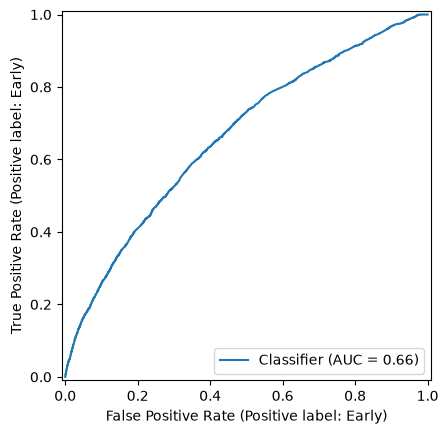

In [113]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

pos_idx = list(final_clf.classes_).index("Early")
y_score = final_clf.predict_proba(X_test)[:, pos_idx]
RocCurveDisplay.from_predictions(y_test, y_score, pos_label="Early")
plt.show()

In [123]:
from sklearn.metrics import classification_report
print( classification_report( y_test, final_lr_clf.predict( X_test ) ) )

              precision    recall  f1-score   support

       Early       0.42      0.01      0.02      2272
       Later       0.89      1.00      0.94     18082

    accuracy                           0.89     20354
   macro avg       0.65      0.51      0.48     20354
weighted avg       0.84      0.89      0.84     20354



In [133]:
from sklearn.metrics import average_precision_score
pos_idx = list(final_lr_clf.classes_).index("Early")
y_score = final_lr_clf.predict_proba(X_test)[:, pos_idx]

average_precision_score( y_test, y_score, pos_label='Early' )

0.20886204024173866

## Day 4 — Compare logistic regression with a tree-based model

### Repeat the previous processi, but to make this a fair comparison, I will use the same, initial test/train split

In [114]:
## save a back up of the final logistic regression model
final_lr_clf = final_clf

In [116]:
X.columns

Index(['num_procedures', 'number_outpatient', 'number_emergency',
       'number_inpatient', 'A1Cresult', 'metformin',
       'discharge_disposition_id', 'diabetesMed', 'admission_source_id',
       'admission_type_id', 'max_glu_serum'],
      dtype='str')

In [120]:
from sklearn.ensemble import RandomForestClassifier
# -------------------------------------------------
# 2. Define the model and preprocessing pipeline
# -------------------------------------------------

clf = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1,
    )),
])

# -------------------------------------------------
# 3. Define which hyperparameters to evaluate
# -------------------------------------------------

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 5],
    'classifier__bootstrap': [True, False],
    "classifier__max_features": ["sqrt", 1.0],
}


# -------------------------------------------------
# 4. Perform CV and select the best hyperparameters
# -------------------------------------------------

inner_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=123
)

grid = GridSearchCV(
    estimator=clf,
    param_grid=param_grid,
    cv=inner_cv,
    scoring="roc_auc",
    refit=True,
    verbose=3,
    n_jobs=10 
)

grid.fit(X_train, y_train, groups=train_groups)


# -------------------------------------------------
# 5. Retrieve the selected configuration
# -------------------------------------------------

print(grid.best_params_)
print(grid.best_score_)

final_clf = grid.best_estimator_


# -------------------------------------------------
# 6. Evaluate on the untouched 20% test set
# -------------------------------------------------

test_probabilities = final_clf.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, test_probabilities)

print("Test AUC:", test_auc)



Fitting 5 folds for each of 144 candidates, totalling 720 fits
[CV 2/5] END classifier__bootstrap=True, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_leaf=1, classifier__min_samples_split=2, classifier__n_estimators=100;, score=0.603 total time=  10.0s
[CV 3/5] END classifier__bootstrap=True, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_leaf=1, classifier__min_samples_split=5, classifier__n_estimators=100;, score=0.615 total time=   9.3s
[CV 2/5] END classifier__bootstrap=True, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_leaf=1, classifier__min_samples_split=5, classifier__n_estimators=200;, score=0.621 total time=  19.9s
[CV 3/5] END classifier__bootstrap=True, classifier__max_depth=None, classifier__max_features=sqrt, classifier__min_samples_leaf=5, classifier__min_samples_split=2, classifier__n_estimators=100;, score=0.660 total time=   8.2s
[CV 3/5] END classifier__boot

In [121]:
print("Test AUC:", test_auc)

Test AUC: 0.6665576740778706


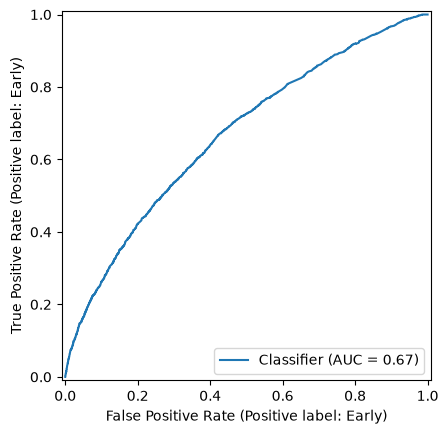

In [122]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

pos_idx = list(final_clf.classes_).index("Early")
y_score = final_clf.predict_proba(X_test)[:, pos_idx]
RocCurveDisplay.from_predictions(y_test, y_score, pos_label="Early")
plt.show()

In [124]:
from sklearn.metrics import classification_report
print( classification_report( y_test, final_clf.predict( X_test ) ) )

              precision    recall  f1-score   support

       Early       0.00      0.00      0.00      2272
       Later       0.89      1.00      0.94     18082

    accuracy                           0.89     20354
   macro avg       0.44      0.50      0.47     20354
weighted avg       0.79      0.89      0.84     20354



/home/phw2006/devel/github_repos/personal_projects/Diabetes_130_US_hospitals_1999-2008/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/phw2006/devel/github_repos/personal_projects/Diabetes_130_US_hospitals_1999-2008/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/phw2006/devel/github_repos/personal_projects/Diabetes_130_US_hospitals_1999-2008/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precisi

In [127]:
from sklearn.metrics import average_precision_score
pos_idx = list(final_clf.classes_).index("Early")
y_score = final_clf.predict_proba(X_test)[:, pos_idx]

average_precision_score( y_test, y_score, pos_label='Early' )

0.2140735701413726

## Conclusion:
**The marginal improvements observed from the RandomForest Classifier don't justify the excessive runtime cost of the grid search required to achieve it.**

# Day 5 - Interpret results and consolidate the modeling workflow
## Tasks:
1. Examine logistic regression coefficients and their directions, accounting for categorical encoding and numerical scaling.
2. Calculate permutation importance for the selected model.
3. Identify the most influential predictors and compare their importance across models.
4. Investigate a few representative false-positive and false-negative predictions.
5. Evaluate the final selected model once on the held-out patient-grouped test set.
6. Summarize model performance, limitations, and questions for Week 4.

In [137]:
model = final_lr_clf[ 'classifier' ]
raw_coefficients = model.coef_
raw_intercept = model.intercept_

# 2. Map features to coefficients for a clean overview
#coef_df = pd.DataFrame({
#    'Feature': X_train.columns,
#    'Coefficient': model.coef_[0]  # Use [0] for binary classification
#})

#print(coef_df)

In [142]:
display( X_train.shape )
model.coef_.shape


(81412, 11)

(1, 68)

In [148]:
# 1. Extract the feature names from your preprocessor or pipeline
# (Assuming 'preprocessor' is the ColumnTransformer step inside your model pipeline)
feature_names = final_lr_clf.named_steps['preprocessor'].get_feature_names_out()

# 2. Get the coefficients from your final model step
coefficients = final_lr_clf.named_steps['classifier'].coef_[0] # Use coef_ for 1D or coef_[0] depending on shape

# 3. Combine them into a readable pandas DataFrame or dictionary
import pandas as pd
coef_mapping = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=False)

print(coef_mapping)


                             Feature  Coefficient
22  cat__discharge_disposition_id_11     2.961583
24  cat__discharge_disposition_id_13     0.922148
25  cat__discharge_disposition_id_14     0.582438
38               cat__diabetesMed_No     0.549616
33  cat__discharge_disposition_id_23     0.505149
..                               ...          ...
13   cat__discharge_disposition_id_2    -0.349644
26  cat__discharge_disposition_id_15    -0.565150
16   cat__discharge_disposition_id_5    -0.740697
32  cat__discharge_disposition_id_22    -1.097844
37  cat__discharge_disposition_id_28    -1.377600

[68 rows x 2 columns]


In [172]:
np.median( abs( coefficients ) )

np.float64(0.11333217719555821)

In [164]:
cuts = np.linspace(0.4, 1, 13)
quantiles=np.quantile( abs( coefficients ), cuts )
pd.DataFrame( { 'cuts':cuts, 'quantiles':quantiles } )

,cuts,quantiles
0,0.40,0.060934
1,0.45,0.082726
2,0.50,0.113332
3,0.55,0.152658
4,0.60,0.164149
5,0.65,0.190565
6,0.70,0.216454
7,0.75,0.274197
8,0.80,0.325543
9,0.85,0.373312


In [205]:
##coef_mapping[ abs( coef_mapping[ "Coefficient" ] ) >= np.median( abs( coefficients ) ) ]
coef_mapping[ abs( coef_mapping[ "Coefficient" ] ) >= 0.3 ]

,Feature,Coefficient
22,cat__discharge_disposition_id_11,2.961583
24,cat__discharge_disposition_id_13,0.922148
25,cat__discharge_disposition_id_14,0.582438
38,cat__diabetesMed_No,0.549616
33,cat__discharge_disposition_id_23,0.505149
11,cat__metformin_Up,0.384031
35,cat__discharge_disposition_id_25,0.374558
44,cat__admission_source_id_5,0.334646
39,cat__diabetesMed_Yes,0.311887
66,cat__max_glu_serum_None,0.301659


### Conclusions:
* Of the reduced feature set that the models were trained on, it's clear that the discharge_disposition was the most predictive

In [185]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    final_lr_clf,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
)

In [198]:
for key in result:
  print( key, ":", result[key].shape)


importances_mean : (11,)
importances_std : (11,)
importances : (11, 10)


In [202]:
pd.DataFrame( {
    "features":X_train.columns,
    "importances_mean":result.importances_mean,
    "importances_std":result.importances_std } ).sort_values(by='importances_mean', ascending=False)

,features,importances_mean,importances_std
3,number_inpatient,0.073439,0.005146
6,discharge_disposition_id,0.071283,0.003233
5,metformin,0.005355,0.001261
7,diabetesMed,0.005121,0.001764
9,admission_type_id,0.003488,0.001273
8,admission_source_id,0.002428,0.000803
4,A1Cresult,0.001574,0.000858
2,number_emergency,0.001428,0.000234
10,max_glu_serum,0.001245,0.000615
0,num_procedures,0.000219,0.000117


### Conclusion: 
* **Both coefficients and `permutation_importance()` indicate that `discharge_disposition_id`, `number_inpatient`, `metformin` and `diabetesMed` have the most predictive power of the features that were provided.**

In [207]:
## examine the mislabeled samples
# Predictions on test data
y_pred = final_lr_clf.predict(X_test)

# Find indices where prediction != true label
mismatched_idx = np.where(y_pred != y_test)[0]


In [212]:
mismatched_idx.shape

(2283,)

In [236]:
idx = mismatched_idx[:5]
pd.concat( 
    [X_test.iloc[ idx ], 
     y_test.iloc[idx], 
     pd.Series(y_pred[idx], index=X_test.index[idx], name="Predicted"),], 
    axis=1 )

,num_procedures,number_outpatient,number_emergency,number_inpatient,A1Cresult,metformin,discharge_disposition_id,diabetesMed,admission_source_id,admission_type_id,max_glu_serum,readmit_30_label,Predicted
12,0,0,1,0,None,Steady,3,Yes,7,1,None,Early,Later
46,3,0,0,2,None,No,5,Yes,4,3,None,Early,Later
68,3,0,0,0,None,No,1,Yes,4,2,None,Early,Later
136,0,0,0,0,>8,No,25,Yes,7,6,None,Early,Later
301,1,0,0,0,None,No,3,No,7,6,Norm,Early,Later


In [224]:
idx = mismatched_idx[:5]

pd.concat([
    X_test.iloc[idx],
    pd.Series(y_pred[idx], index=X_test.index[idx], name="Predicted"),
    y_test.iloc[idx].rename("Actual"),
], axis=1)

,num_procedures,number_outpatient,number_emergency,number_inpatient,A1Cresult,metformin,discharge_disposition_id,diabetesMed,admission_source_id,admission_type_id,max_glu_serum,Predicted,Actual
12,0,0,1,0,None,Steady,3,Yes,7,1,None,Later,Early
46,3,0,0,2,None,No,5,Yes,4,3,None,Later,Early
68,3,0,0,0,None,No,1,Yes,4,2,None,Later,Early
136,0,0,0,0,>8,No,25,Yes,7,6,None,Later,Early
301,1,0,0,0,None,No,3,No,7,6,Norm,Later,Early


In [218]:
# Get predicted probabilities for each class
y_probs = final_lr_clf.predict_proba(X_test)

y_probs[:10]
# Look at high-confidence errors (e.g., predicted class 1 with prob > 0.8, but true label is 0)
#confidence_for_true_class = y_probs[np.arange(len(y_test)), y_test]

# Samples where the model is very confident (e.g., < 0.1 probability for the true class)
#suspicious_indices = np.where(confidence_for_true_class < 0.15)[0]


array([[0.10935781, 0.89064219],
       [0.11761349, 0.88238651],
       [0.10689648, 0.89310352],
       [0.13227284, 0.86772716],
       [0.0640772 , 0.9359228 ],
       [0.0733291 , 0.9266709 ],
       [0.08948287, 0.91051713],
       [0.09591701, 0.90408299],
       [0.26489727, 0.73510273],
       [0.06746755, 0.93253245]])